# DSCO Olympiads 2026 - Tim seamen

Target: `at_risk`, metrik F1. Notebook ini membaca `train.csv`, `test.csv`, `sample_submission.csv` dan menghasilkan `submission_final_exp30.csv`.

Alur:
1. EDA
2. Preprocessing
3. Model tahap 1 (baseline)
4. Feature engineering
5. Model selection
6. Evaluasi
7. Training final dan submission

In [1]:
import os
os.environ.setdefault("MKL_THREADING_LAYER", "SEQUENTIAL")  # env conda kami crash tanpa ini

import warnings, time
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold
from sklearn.base import clone
from sklearn.metrics import roc_auc_score, log_loss, f1_score, precision_score, recall_score, confusion_matrix
from sklearn.neural_network import MLPClassifier
from joblib import Parallel, delayed, parallel_config
import lightgbm as lgb, xgboost as xgb, catboost as cb

TARGET = "at_risk"
THRESHOLD = 0.39

## 1. EDA

In [2]:
train, test, sub = pd.read_csv("train.csv"), pd.read_csv("test.csv"), pd.read_csv("sample_submission.csv")
print("train:", train.shape, " test:", test.shape)
print("jumlah NaN:", train.isna().sum().sum(), test.isna().sum().sum())
print("proporsi at_risk:", round(train[TARGET].mean(), 3))
train.describe().T.round(2)

train: (26086, 64)  test: (6502, 63)
jumlah NaN: 0 0
proporsi at_risk: 0.527


,count,mean,std,min,25%,50%,75%,max
id,26086.0,13047.63,7531.75,1.0,6526.25,13048.50,19569.75,26091.00
num_of_prev_attempts,26086.0,0.16,0.48,0.0,0.00,0.00,0.00,6.00
studied_credits,26086.0,79.77,41.03,30.0,60.00,60.00,120.00,655.00
module_presentation_length,26086.0,256.03,13.16,234.0,241.00,262.00,268.00,269.00
registration_days_from_start,26086.0,-69.38,49.22,-322.0,-101.00,-57.00,-29.00,167.00
assessments_due_total,26086.0,1.04,0.20,1.0,1.00,1.00,1.00,2.00
assessments_due_Assessment_1,26086.0,0.18,0.38,0.0,0.00,0.00,0.00,1.00
assessments_due_Assessment_2,26086.0,0.86,0.34,0.0,1.00,1.00,1.00,1.00
submitted_count,26086.0,1.03,0.16,1.0,1.00,1.00,1.00,2.00
late_submission_count,26086.0,0.16,0.37,0.0,0.00,0.00,0.00,2.00


Kelas cukup seimbang (52.7% at_risk). Kalau semua ditebak 1, F1 sudah sekitar 0.69, jadi itu batas bawah yang harus dilewati.

### Cek kualitas data

In [3]:
print("kolom konstan:", [c for c in train.columns if train[c].nunique() == 1])
for a, b in [("median_score", "avg_score"), ("median_submission_delay", "avg_submission_delay"),
             ("avg_interactions_per_active_day", "avg_daily_interactions")]:
    print(f"{a} == {b}: {np.isclose(train[a], train[b]).all()}")
print("baris duplikat (tanpa id):", train.drop(columns="id").duplicated().sum())
for c in ["code_module", "highest_education", "region", "imd_band"]:
    print(c, sorted(pd.concat([train[c], test[c]]).unique()))

kolom konstan: ['submitted_Assessment_2', 'submitted_Assessment_1']
median_score == avg_score: True
median_submission_delay == avg_submission_delay: True
avg_interactions_per_active_day == avg_daily_interactions: True
baris duplikat (tanpa id): 4
code_module ['GGG', 'M01', 'M02', 'M03', 'M04', 'M05', 'M06', 'M07']
highest_education ['-', 'A Level', 'A level', 'HE Qualification', 'Lower Than A Level', 'Post Graduate Qualification']
region ['Region 10', 'Region 3', 'Region 4', 'Region1', 'Region11', 'Region12', 'Region13', 'Region5', 'Region6', 'Region7', 'Region8', 'Region9', 'region2']
imd_band ['-', '0-10%', '20-30%', '30-40%', '40-50%', '50-60%', '60-70%', '70-80%', '80-90%', '90-100%', '?']


Yang perlu dibereskan:
- 2 kolom konstan dan 3 kolom yang isinya sama persis dengan kolom lain
- `GGG` cuma muncul di test, ini sebenarnya M07
- penulisan `A level` / `A Level` dan region (`Region 3`, `region2`) tidak seragam
- `-` di highest_education kami anggap "no formal quals", `-` di imd_band adalah bin 10-20% (bin itu tidak ada di data)

### Nilai isian dan segmen siswa

In [4]:
no_vle = (train.interaction_volume == 182) & (train.active_days == 10)
print(f"baris dengan data VLE isian (volume 182, active_days 10): {no_vle.mean():.1%}")
print("avg_score saat has_score = 0:", train.avg_score[train.has_score == 0].value_counts().head(3).to_dict())
seg = np.where(no_vle, "tanpa VLE", np.where(train.has_score == 0, "tanpa nilai", "lengkap"))
train.groupby(seg)[TARGET].agg(["size", "mean"]).round(3)

baris dengan data VLE isian (volume 182, active_days 10): 14.3%
avg_score saat has_score = 0: {77.0: 10046}


,size,mean
lengkap,15966,0.407
tanpa VLE,3740,0.952
tanpa nilai,6380,0.579


Sekitar 14% baris tidak punya data VLE asli (semua kolom VLE diisi nilai yang sama), dan hampir semuanya at_risk.
Baris tanpa nilai tugas diisi avg_score 77. Segmen "lengkap" paling susah ditebak karena at_risk-nya mendekati 40%.

### Label modul yang salah di train

In [5]:
g = np.select([train.id.between(25937, 26080), train.id.eq(24112)], ["id 25937-26080", "id 24112"],
              train.code_module + "|" + train.code_presentation)
d = train.assign(grup=g)
d = d[d.grup.isin(["M04|P22", "M07|P22", "id 25937-26080", "id 24112", "M07|P12"])]
d.groupby("grup").agg(n=("id", "size"), id_min=("id", "min"), id_max=("id", "max"),
                      modul=("code_module", lambda s: s.mode()[0]), credits=("studied_credits", "mean"),
                      perempuan=("gender", lambda s: (s == "F").mean()), has_score=("has_score", "mean"),
                      at_risk=(TARGET, "mean")).round(2)

,n,id_min,id_max,modul,credits,perempuan,has_score,at_risk
grup,,,,,,,,
M04|P22,1883,22228,24110,M04,92.67,0.18,0.7,0.52
M07|P12,756,24111,24867,M07,34.25,0.82,0.0,0.38
M07|P22,454,25494,26091,M07,33.30,0.80,0.0,0.41
id 24112,1,24112,24112,M05,30.00,0.00,0.0,0.00
id 25937-26080,144,25937,26080,M04,33.12,0.85,0.0,0.44


`id` urut per blok modul-presentasi. Baris id 25937-26080 tertulis M04 tapi posisinya di tengah blok M07|P22, dan profilnya
(credits sekitar 33, mayoritas perempuan, tidak ada nilai) mirip M07, bukan M04. Hal yang sama untuk id 24112.
Jadi modul baris-baris ini kami ubah ke M07.

### Target vs fitur

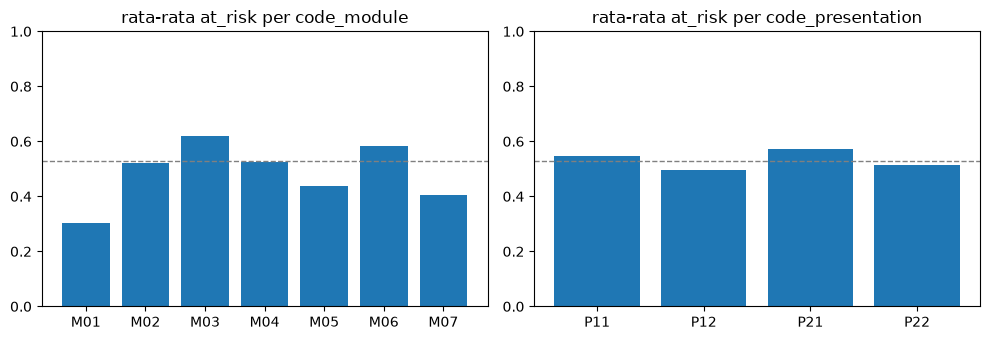

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
for a, c in zip(ax, ["code_module", "code_presentation"]):
    r = train.groupby(c)[TARGET].mean().sort_index()
    a.bar(r.index, r.values)
    a.axhline(train[TARGET].mean(), color="gray", ls="--", lw=1)
    a.set_title(f"rata-rata at_risk per {c}")
    a.set_ylim(0, 1)
plt.tight_layout()
plt.show()

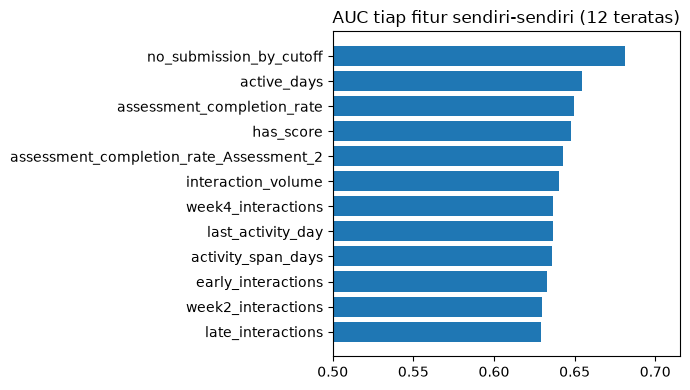

In [7]:
auc_uni = {c: abs(roc_auc_score(train[TARGET], train[c]) - 0.5) + 0.5
           for c in train.select_dtypes("number").columns if c not in ("id", TARGET) and train[c].nunique() > 1}
top = pd.Series(auc_uni).sort_values().tail(12)
plt.figure(figsize=(7, 4))
plt.barh(top.index, top.values)
plt.xlim(0.5, None)
plt.title("AUC tiap fitur sendiri-sendiri (12 teratas)")
plt.tight_layout()
plt.show()

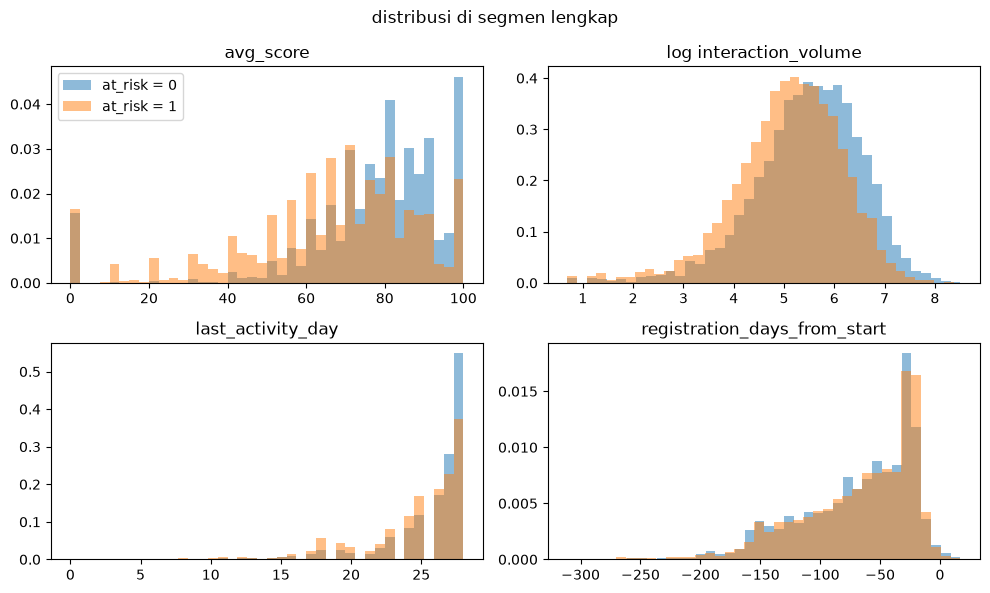

In [8]:
ok = ~no_vle & (train.has_score == 1)
cols = ["avg_score", "interaction_volume", "last_activity_day", "registration_days_from_start"]
fig, ax = plt.subplots(2, 2, figsize=(10, 6))
for a, c in zip(ax.ravel(), cols):
    for yv in (0, 1):
        v = train.loc[ok & (train[TARGET] == yv), c]
        if c == "interaction_volume":
            v = np.log1p(v)
        a.hist(v, bins=40, alpha=0.5, density=True, label=f"at_risk = {yv}")
    a.set_title(("log " if c == "interaction_volume" else "") + c)
ax[0, 0].legend()
plt.suptitle("distribusi di segmen lengkap")
plt.tight_layout()
plt.show()

Nilai dan aktivitas VLE (terutama aktivitas terakhir) adalah pembeda utama. Demografi saja lemah.

### Train vs test

In [9]:
num = ["avg_score", "interaction_volume", "active_days", "registration_days_from_start", "studied_credits"]
print(pd.DataFrame({"train": train[num].mean(), "test": test[num].mean()}).round(2))
pd.DataFrame({"train": train.code_module.value_counts(normalize=True),
              "test": test.code_module.replace({"GGG": "M07"}).value_counts(normalize=True)}).sort_index().round(3).T

                               train    test
avg_score                      74.05   74.74
interaction_volume            270.12  269.32
active_days                    10.96   10.86
registration_days_from_start  -69.38  -69.41
studied_credits                79.77   79.70


code_module,M01,M02,M03,M04,M05,M06,M07
train,0.023,0.244,0.137,0.242,0.090,0.194,0.070
test,0.022,0.236,0.133,0.247,0.091,0.185,0.085


Distribusi train dan test hampir sama, jadi hasil cross-validation di train bisa dipercaya untuk memilih model dan threshold.

## 2. Preprocessing
Buang kolom konstan/kembar, seragamkan kategori, perbaiki label modul, buang 4 baris duplikat, dan tambah flag `no_vle`.

In [10]:
DROP = ["submitted_Assessment_1", "submitted_Assessment_2",
        "median_score", "median_submission_delay", "avg_interactions_per_active_day"]
NOMINAL = ["code_module", "code_presentation", "gender", "region", "disability", "imd_band", "highest_education", "age_band"]
FIXED_IDS = list(range(25937, 26081)) + [24112]

def clean(df):
    df = df.copy()
    df["code_module"] = df.code_module.replace({"GGG": "M07"})
    df["highest_education"] = df.highest_education.str.strip().str.lower().replace({"-": "no formal quals"})
    df["region"] = df.region.str.lower().str.replace(" ", "", regex=False)
    df["imd_raw"] = df.imd_band   # disimpan untuk mencocokkan siswa
    df["imd_band"] = df.imd_band.replace({"-": "10-20%"})
    return df.drop(columns=DROP)

train_fix = train.copy()
train_fix.loc[train_fix.id.isin(FIXED_IDS), "code_module"] = "M07"
full = clean(pd.concat([train_fix.assign(is_test=0), test.assign(is_test=1)], ignore_index=True))
dup = full[full.is_test.eq(0)].drop(columns=["id", "is_test", "imd_raw"]).duplicated()
full = full.drop(index=dup[dup].index).reset_index(drop=True)
for c in NOMINAL:
    full[c] = pd.Categorical(full[c], categories=sorted(full[c].unique()))
BASE = [c for c in full.columns if c not in ("id", TARGET, "is_test", "imd_raw")]
full["no_vle"] = ((full.interaction_volume == 182) & (full.active_days == 10)).astype(int)

trm = full.is_test.eq(0).values; tri = np.where(trm)[0]; N = len(full)
y_all = full.loc[trm, TARGET].astype(int).values
yfull = np.full(N, np.nan); yfull[trm] = y_all
assert (full.loc[~trm, "id"].values == test.id.values).all()

# baris di sekitar blok yang diperbaiki tidak dipakai untuk menghitung skor CV (di test tidak ada kasus seperti ini)
ids_tr = full.loc[trm, "id"].values
CLEAN = ~((ids_tr >= 25937) & (ids_tr <= 26091) | (ids_tr == 24112))

lg = lambda p: np.log(np.clip(p, 1e-6, 1 - 1e-6) / (1 - np.clip(p, 1e-6, 1 - 1e-6)))
sig = lambda x: 1 / (1 + np.exp(-x))
print(len(BASE), "fitur | train", trm.sum(), "| test", (~trm).sum(), "| duplikat dibuang", int(dup.sum()))

57 fitur | train 26082 | test 6502 | duplikat dibuang 4


## 3. Model tahap 1

Model awal pakai fitur asli saja. Baseline pertama kami adalah 95% rata-rata tree (LightGBM 10 seed, XGBoost 10 seed,
CatBoost 5 seed) + 5% logistic regression. Bagian tree dari baseline itu lalu digabung 50:50 dengan MLP (2 setting x 10 seed). Hasilnya dipakai lagi di tahap 2: kalau label "pasangan" seorang siswa tidak diketahui
(ada di fold validasi atau di test), kami pakai prediksi model ini sebagai gantinya.

Catatan: model tahap 1 dibuat sebelum kami menemukan label modul yang salah, jadi tahap ini masih memakai modul aslinya.

In [11]:
SEEDS_GBDT = [42, 7, 2026, 1, 13, 99, 123, 314, 777, 2024]
SEEDS_CAT = [42, 7, 2026, 1, 13]
WEEKS = [f"week{i}_interactions" for i in range(1, 5)]

orig_module = pd.concat([train, test]).set_index("id").code_module.replace({"GGG": "M07"})
X1 = full[BASE].copy()
X1["code_module"] = pd.Categorical(full.id.map(orig_module).values, categories=full.code_module.cat.categories)
X1_tr, X1_te = X1[trm].reset_index(drop=True), X1[~trm].reset_index(drop=True)
SPLITS1 = list(RepeatedStratifiedKFold(n_splits=5, n_repeats=1, random_state=42).split(np.zeros(len(y_all)), y_all))

class CatBoostDF(cb.CatBoostClassifier):
    def _cast(self, X):
        X = X.copy()
        for c in NOMINAL: X[c] = X[c].astype(str)
        return X
    def fit(self, X, y=None, **kw): return super().fit(self._cast(X), y, cat_features=NOMINAL, **kw)
    def predict_proba(self, X, *a, **kw): return super().predict_proba(self._cast(X), *a, **kw)

TREES = {
    "LightGBM": (lgb.LGBMClassifier(n_estimators=1300, learning_rate=0.01, num_leaves=15, min_child_samples=40,
                                    subsample=0.7, subsample_freq=1, colsample_bytree=0.5, reg_lambda=1, reg_alpha=0,
                                    verbose=-1), "random_state", SEEDS_GBDT),
    "XGBoost": (xgb.XGBClassifier(tree_method="hist", enable_categorical=True, eval_metric="auc", n_estimators=1000,
                                  learning_rate=0.01, max_depth=5, min_child_weight=5, subsample=0.7, colsample_bytree=0.5,
                                  gamma=0.5, reg_lambda=0, reg_alpha=0, n_jobs=-1), "random_state", SEEDS_GBDT),
    "CatBoost": (CatBoostDF(iterations=800, learning_rate=0.05, depth=6, verbose=0, thread_count=-1,
                            allow_writing_files=False), "random_seed", SEEDS_CAT),
}

def tree_pred(X, y, X_preds):
    out = [np.zeros(len(Xp)) for Xp in X_preds]
    for model, key, seeds in TREES.values():
        for s in seeds:
            m = clone(model).set_params(**{key: s}).fit(X, y)
            for o, Xp in zip(out, X_preds): o += m.predict_proba(Xp)[:, 1] / len(seeds) / len(TREES)
    return out

SCORE_LIKE = [c for c in BASE if ("score" in c or "delay" in c) and c != "has_score"]
VLE_LIKE = ["interaction_volume", "active_days", "unique_sites", "unique_activity_types", "avg_daily_interactions",
            "max_daily_interactions", "interaction_variability", "first_activity_day", "last_activity_day", *WEEKS,
            "interaction_trend", "early_interactions", "late_interactions", "late_to_early_interactions_ratio",
            "active_weeks", "avg_interactions_per_active_week", "activity_span_days"]
NUMERIC = [c for c in BASE if c not in NOMINAL]

def design(X, prep=None):
    # input untuk MLP: one-hot kategori + angka (log, distandarkan). nilai isian jadi 0 dan diberi flag
    Z = X[NUMERIC].astype(float).copy()
    nv = (X[WEEKS].sum(axis=1) != X.interaction_volume).values
    Z.loc[X.has_score.eq(0).values, SCORE_LIKE] = np.nan
    Z.loc[nv, VLE_LIKE] = np.nan
    V = np.sign(Z.values) * np.log1p(np.abs(Z.values))
    if prep is None: prep = dict(mu=np.nanmean(V, 0), sd=np.nanstd(V, 0) + 1e-9)
    parts = [np.ones((len(X), 1)), nv[:, None].astype(float)]
    parts += [np.eye(len(X[c].cat.categories))[X[c].cat.codes.values] for c in NOMINAL]
    parts += [np.nan_to_num((V - prep["mu"]) / prep["sd"]), np.isnan(Z.values).astype(float)]
    return np.hstack(parts), prep

MLP_PARAMS = {
    "MLP-a": dict(hidden=(128, 64), act="relu", alpha=0.3, lr=1e-3, batch=200),
    "MLP-b": dict(hidden=(128, 64), act="relu", alpha=0.7137460343256068, lr=0.00020410395328634794, batch=200),
}

def fit_lr(A, y, C=1.0, max_iter=30):
    # logistic regression L2 dengan Newton-Raphson
    pen = np.full(A.shape[1], 1 / C); pen[0] = 0
    w = np.zeros(A.shape[1])
    for _ in range(max_iter):
        p = 1 / (1 + np.exp(-np.clip(A @ w, -30, 30)))
        g = A.T @ (p - y) + pen * w
        H = (A * (p * (1 - p))[:, None]).T @ A + np.diag(pen + 1e-8)
        step = np.linalg.solve(H, g); w -= step
        if np.abs(step).max() < 1e-6: break
    return w

lr_proba = lambda A, w: 1 / (1 + np.exp(-np.clip(A @ w, -30, 30)))

def fit_net(A, y, p, seed):
    return MLPClassifier(p["hidden"], activation=p["act"], alpha=p["alpha"], learning_rate_init=p["lr"],
                         batch_size=p["batch"], early_stopping=True, n_iter_no_change=15, max_iter=300,
                         random_state=seed).fit(A, y)

In [12]:
t0 = time.time()
TASKS = [(a, X1_tr.iloc[b]) for a, b in SPLITS1] + [(np.arange(len(y_all)), X1_te)]   # 5 fold + latih penuh untuk test
TREE_P = []
for k, (a, Xp) in enumerate(TASKS):
    TREE_P.append(tree_pred(X1_tr.iloc[a], y_all[a], [Xp])[0])
    print(f"tree {k + 1}/{len(TASKS)} selesai ({time.time() - t0:.0f} detik)", flush=True)

DES = []
for a, Xp in TASKS:
    A, prep = design(X1_tr.iloc[a]); DES.append((A, design(Xp, prep)[0]))
LR_P = [lr_proba(Ap, fit_lr(A, y_all[a].astype(float))) for (a, _), (A, Ap) in zip(TASKS, DES)]
jobs = [(t, name, s) for t in range(len(TASKS)) for name in MLP_PARAMS for s in range(10)]
with parallel_config(backend="loky", inner_max_num_threads=1):
    nets = Parallel(n_jobs=20)(delayed(fit_net)(DES[t][0], y_all[TASKS[t][0]], MLP_PARAMS[n], s) for t, n, s in jobs)
MLP_P = {n: [np.zeros(len(Xp)) for _, Xp in TASKS] for n in MLP_PARAMS}
for (t, n, s), net in zip(jobs, nets):
    MLP_P[n][t] += net.predict_proba(DES[t][1])[:, 1] / 10

def to_oof(preds):
    oof = np.zeros(len(y_all))
    for (_, b), p in zip(SPLITS1, preds): oof[b] = p
    return oof, preds[-1]

W_LR = 0.05
TREE_OOF, TREE_TEST = to_oof(TREE_P)
LR_OOF, LR_TEST = to_oof(LR_P)
BASE_OOF = (1 - W_LR) * TREE_OOF + W_LR * LR_OOF      # baseline 95/5
BASE_TEST = (1 - W_LR) * TREE_TEST + W_LR * LR_TEST
# bagian tree diambil lagi dari baseline, mengikuti urutan hitungan di pipeline eksperimen kami
TREE_OOF = (BASE_OOF - W_LR * LR_OOF) / (1 - W_LR)
TREE_TEST = (BASE_TEST - W_LR * LR_TEST) / (1 - W_LR)
MLP_OOF = np.mean([to_oof(p)[0] for p in MLP_P.values()], axis=0)
MLP_TEST = np.mean([to_oof(p)[1] for p in MLP_P.values()], axis=0)
p13 = np.zeros(N)
p13[trm] = sig(0.5 * lg(TREE_OOF) + 0.5 * lg(MLP_OOF))
p13[~trm] = sig(0.5 * lg(TREE_TEST) + 0.5 * lg(MLP_TEST))
for name, p in [("tree", TREE_OOF), ("LR", LR_OOF), ("baseline 95/5", BASE_OOF), ("MLP", MLP_OOF), ("tree + MLP", p13[trm])]:
    print(f"AUC OOF {name}: {roc_auc_score(y_all[CLEAN], p[CLEAN]):.4f}")

tree 1/6 selesai (196 detik)


tree 2/6 selesai (470 detik)


tree 3/6 selesai (689 detik)


tree 4/6 selesai (880 detik)


tree 5/6 selesai (1080 detik)


tree 6/6 selesai (1379 detik)


AUC OOF tree: 0.8465
AUC OOF LR: 0.8354
AUC OOF baseline 95/5: 0.8467
AUC OOF MLP: 0.8468
AUC OOF tree + MLP: 0.8479


## 4. Feature engineering

Satu siswa bisa muncul di lebih dari satu baris: mengulang modul yang sama di presentasi berikutnya (retake), atau ambil
dua modul sekaligus di presentasi yang sama (partner). Tidak ada id siswa, jadi baris kami cocokkan lewat demografi yang
sama persis. Posisi `id` di dalam blok modul-presentasi (`pct`) ikut dipakai sebagai petunjuk kemiripan, karena `id` urut
mengikuti siswa.

Fitur yang dibuat:
- retake: apakah ada baris "kembaran" di presentasi berikutnya dengan `num_of_prev_attempts` + 1, serta perilaku di percobaan sebelumnya
- partner: rata-rata aktivitas VLE/nilai dan label at_risk partner. Label hanya dipakai kalau partner ada di data latih
  fold itu, kalau tidak pakai prediksi tahap 1
- jumlah siswa dengan profil sama per blok, ranking tanggal registrasi, dan versi ordinal imd/umur/pendidikan

In [13]:
half = np.where(full.id < 26092, 0, np.where(full.id < 29348, 1, 2))   # id test terbagi 2 rentang
full["pct"] = full.assign(h=half).groupby(["h", "code_module", "code_presentation"], observed=True).id.rank(pct=True)

# retake: modul sama, presentasi beda
T_MAP = {"P11": 0, "P12": 1, "P21": 2, "P22": 3}
key = ["code_module", "gender", "region", "highest_education", "imd_raw", "disability"]
g = full[key + ["code_presentation", "num_of_prev_attempts", "age_band", "pct"]].copy()
g["t"] = g.code_presentation.map(T_MAP).astype(int); g["age"] = g.age_band.cat.codes; g["i"] = g.index
for c in key: g[c] = g[c].astype(str)
g = g.drop(columns=["code_presentation", "age_band"])
m = g.merge(g, on=key, suffixes=("", "_n"))
fut = m[(m.t_n > m.t) & (m.num_of_prev_attempts_n == m.num_of_prev_attempts + 1) & (m.age <= m.age_n)].copy()
past = m[(m.t_n < m.t) & (m.num_of_prev_attempts_n == m.num_of_prev_attempts - 1) & (m.age >= m.age_n)].copy()
for d in (fut, past):
    d["w"] = 1 / d.i_n.map(d.groupby("i_n").size()); d["d"] = (d.pct - d.pct_n).abs(); d["k"] = np.exp(-d.d / 0.05)
G = pd.DataFrame(index=full.index)
G["pct"] = full.pct
G["rt_soft"] = fut.groupby("i").w.sum().reindex(full.index, fill_value=0)
G["rt_max"] = fut.groupby("i").w.max().reindex(full.index, fill_value=0)
G["rt_k"] = fut.groupby("i").k.max().reindex(full.index, fill_value=0)
G["rt_dmin"] = fut.groupby("i").d.min().reindex(full.index, fill_value=1)
G["rtp_max"] = past.groupby("i").w.max().reindex(full.index, fill_value=0)
G["rtp_k"] = past.groupby("i").k.max().reindex(full.index, fill_value=0)

# partner: presentasi sama, modul lain
pkey = ["gender", "region", "highest_education", "imd_raw", "disability", "age_band", "code_presentation", "studied_credits"]
h = full[pkey + ["code_module", "registration_days_from_start", "pct"]].copy(); h["i"] = h.index
for c in pkey + ["code_module"]: h[c] = h[c].astype(str)
pa = h.merge(h, on=pkey, suffixes=("", "_n")); pa = pa[pa.code_module != pa.code_module_n].copy()
pa["same_reg"] = (pa.registration_days_from_start == pa.registration_days_from_start_n)
pa["kw"] = np.exp(-(pa.pct - pa.pct_n).abs() / 0.03) * np.where(pa.same_reg, 1, 0.3)
pl = pa[pa.kw > 0.05].reset_index(drop=True)
sp = pa[pa.same_reg].copy(); sp["w1"] = 1.0   # partner dengan tanggal registrasi sama persis
print(f"pasangan partner: {len(pl)}, baris yang punya partner: {pl.i.nunique()} ({pl.i.nunique() / N:.1%})")

def wmean(links, wcol, vals, default=np.nan):
    d = pd.DataFrame({"i": links.i.values, "w": links[wcol].values})
    V = np.atleast_2d(vals.T).T if vals.ndim == 1 else vals
    num = pd.DataFrame(V[links.i_n.values] * d.w.values[:, None]).groupby(d.i.values).sum()
    den = d.groupby("i").w.sum()
    out = np.full((N, V.shape[1]), default, float); out[den.index] = num.loc[den.index].values / den.values[:, None]
    return out

PCOLS = ["interaction_volume", "active_days", "last_activity_day", "week4_interactions", "avg_score", "has_score",
         "submitted_count", "weighted_score_total", "no_vle", "registration_days_from_start"]
pv = full[PCOLS].astype(float).values
pv[full.has_score.values == 0, PCOLS.index("avg_score")] = np.nan
pvn = np.nan_to_num(pv, nan=0.0)
PM = wmean(pl, "kw", pvn)
for j, c in enumerate(PCOLS): G["pt_" + c] = PM[:, j]
G["pt_w"] = pl.groupby("i").kw.sum().reindex(full.index, fill_value=0)
G["pt_max"] = pl.groupby("i").kw.max().reindex(full.index, fill_value=0)
G["pt_vol_ratio"] = np.log1p(full.interaction_volume) - np.log1p(G.pt_interaction_volume)
PAST = wmean(past[past.k > 0.05], "k", pvn[:, [0, 1, 4, 5, 8]])   # perilaku di percobaan sebelumnya
for j, c in enumerate(["vol", "days", "score", "has_score", "no_vle"]): G["past_" + c] = PAST[:, j]
G.loc[full.id.isin(FIXED_IDS).values, "pct"] = np.nan   # posisi id baris yang modulnya diperbaiki tidak bermakna

# frekuensi dan ordinal
F = pd.DataFrame(index=full.index)
blk = ["code_module", "code_presentation"]
dem = ["gender", "region", "highest_education", "imd_raw", "disability", "age_band"]
s = full[blk + dem + ["registration_days_from_start", "studied_credits"]].astype(str)
F["n_twin_blk"] = s.groupby(blk + dem)["registration_days_from_start"].transform("size")
F["n_regday_blk"] = s.groupby(blk + ["registration_days_from_start"])["gender"].transform("size")
F["n_twin_pres"] = s.groupby(["code_presentation"] + dem + ["studied_credits"])["gender"].transform("size")
F["reg_rank_blk"] = full.groupby(blk, observed=True).registration_days_from_start.rank(pct=True)
F["n_pa_cand"] = pa.groupby("i").size().reindex(full.index, fill_value=0)
F["n_fut_cand"] = fut.groupby("i").size().reindex(full.index, fill_value=0)
F["n_past_cand"] = past.groupby("i").size().reindex(full.index, fill_value=0)
O = pd.DataFrame(index=full.index)
O["imd_ord"] = full.imd_band.astype(str).str.extract(r"(\d+)")[0].astype(float)
O["age_ord"] = full.age_band.astype(str).map({"0-35": 0, "35-55": 1, "55<=": 2}).astype(float)
O["edu_ord"] = full.highest_education.astype(str).map({"no formal quals": 0, "lower than a level": 1, "a level": 2,
                                                      "he qualification": 3, "post graduate qualification": 4}).astype(float)

COLS = ["pct", "rt_soft", "rt_max", "rt_k", "rt_dmin", "rtp_max", "rtp_k",
        "past_vol", "past_days", "past_score", "past_has_score", "past_no_vle"] + [c for c in G.columns if c.startswith("pt_")]

def label_feats(known):
    # label partner kalau partner ada di data latih, kalau tidak pakai prediksi tahap 1
    v = np.where(known, yfull, p13)
    pk = pl.copy(); pk["kn"] = known[pk.i_n.values]
    out = pd.DataFrame(index=full.index)
    out["ptl_mean"] = wmean(pk, "kw", v)[:, 0]
    kk = pk[pk.kn]; out["ptl_known_w"] = kk.groupby("i").kw.sum().reindex(full.index, fill_value=0)
    out["ptl_known_mean"] = wmean(kk, "kw", v)[:, 0] if len(kk) else np.nan
    return out

def make_X(known):
    X = full[BASE + ["no_vle"]].copy()
    for c in COLS: X[c] = G[c].values
    X = pd.concat([X, label_feats(known)], axis=1)
    X["pts_mean"] = wmean(sp, "w1", np.where(known, yfull, p13))[:, 0]
    return pd.concat([X, F, O], axis=1)

print("jumlah fitur tahap 2:", make_X(trm.copy()).shape[1])

pasangan partner: 7568, baris yang punya partner: 5945 (18.2%)


jumlah fitur tahap 2: 97


In [14]:
r = pd.DataFrame({"retake": pd.cut(G.rt_max[trm], [-0.01, 0, 0.5, 1], labels=["tidak ada", "ragu-ragu", "jelas"]),
                  "at_risk": y_all})
print(r.groupby("retake", observed=True).at_risk.agg(["size", "mean"]).round(3))
both = sp[trm[sp.i.values] & trm[sp.i_n.values]]
print("korelasi label dengan partner:", round(np.corrcoef(yfull[both.i], yfull[both.i_n])[0, 1], 3))

            size   mean
retake                 
tidak ada  19840  0.510
ragu-ragu   5772  0.565
jelas        470  0.785
korelasi label dengan partner: 0.358


Siswa yang jelas punya retake di presentasi berikutnya 78.5% at_risk (rata-rata 52.7%), masuk akal karena mereka mengulang.
Label siswa dengan partnernya juga berkorelasi (sekitar 0.36).

## 5. Model selection

Semua kandidat dinilai dengan 5-fold CV yang diulang 3 kali (fold dan seed sama untuk semua model). Skor dihitung di baris
train yang bersih. Fitur label partner dibuat ulang di tiap fold supaya label fold validasi tidak bocor.

Hyperparameter LightGBM/XGBoost/CatBoost didapat dari Optuna (minimasi logloss) di fold yang berbeda dari fold evaluasi ini.

In [15]:
BP = {
    "lgbm": dict(params={'num_leaves': 25, 'min_child_samples': 70, 'subsample': 0.9109447768829689, 'colsample_bytree': 0.5390434016886803, 'reg_lambda': 0.01749597931509718, 'reg_alpha': 0.8040405339959221}, iters=623, lr=0.02),
    "xgb": dict(params={'max_depth': 6, 'min_child_weight': 9.326700953967492, 'subsample': 0.8978763396089783, 'colsample_bytree': 0.24413712087008094, 'gamma': 1.1015683836561296, 'reg_lambda': 0.22196528871926036, 'reg_alpha': 0.04899838664275449}, iters=754, lr=0.02),
    "cat": dict(params={'depth': 8, 'l2_leaf_reg': 15.860946263718267, 'random_strength': 1.1910134942574713, 'bagging_temperature': 1.4125136345515543}, iters=558, lr=0.05),
}

def model(k, seed):
    p, n, lr = BP[k]["params"], BP[k]["iters"], BP[k]["lr"]
    if k == "lgbm": return lgb.LGBMClassifier(n_estimators=n, learning_rate=lr, subsample_freq=1, verbose=-1, n_jobs=8, random_state=seed, **p)
    if k == "xgb": return xgb.XGBClassifier(tree_method="hist", enable_categorical=True, n_estimators=n, learning_rate=lr, n_jobs=8, random_state=seed, **p)
    return cb.CatBoostClassifier(iterations=n, learning_rate=lr, verbose=0, thread_count=8, allow_writing_files=False, random_seed=seed, **p)

def lgbm_et(seed):
    p, n, lr = BP["lgbm"]["params"], BP["lgbm"]["iters"], BP["lgbm"]["lr"]
    return lgb.LGBMClassifier(n_estimators=int(n * 1.6), learning_rate=lr, subsample_freq=1, extra_trees=True, verbose=-1,
                              n_jobs=8, random_state=seed, **p)

def cat_cast(X):
    X = X.copy()
    for c in NOMINAL: X[c] = X[c].astype(str)
    return X

In [16]:
REPS = 3; t0 = time.time()
oof = {k: np.zeros((REPS, len(y_all))) for k in ["lgbm_base", "lgbm", "xgb", "cat", "lgbm_et"]}
for rep in range(REPS):
    for a, b in StratifiedKFold(5, shuffle=True, random_state=300 + rep).split(tri, y_all):
        known = np.zeros(N, bool); known[tri[a]] = True
        Xt = make_X(known)[trm]; Xc = cat_cast(Xt); Xb = Xt[BASE + ["no_vle"]]
        oof["lgbm_base"][rep, b] = model("lgbm", rep).fit(Xb.iloc[a], y_all[a]).predict_proba(Xb.iloc[b])[:, 1]
        oof["lgbm"][rep, b] = model("lgbm", rep).fit(Xt.iloc[a], y_all[a]).predict_proba(Xt.iloc[b])[:, 1]
        oof["xgb"][rep, b] = model("xgb", rep).fit(Xt.iloc[a], y_all[a]).predict_proba(Xt.iloc[b])[:, 1]
        oof["cat"][rep, b] = model("cat", rep).fit(Xc.iloc[a], y_all[a], cat_features=NOMINAL).predict_proba(Xc.iloc[b])[:, 1]
        oof["lgbm_et"][rep, b] = lgbm_et(rep).fit(Xt.iloc[a], y_all[a]).predict_proba(Xt.iloc[b])[:, 1]
    print(f"repeat {rep} selesai ({time.time() - t0:.0f} detik)", flush=True)

repeat 0 selesai (181 detik)


repeat 1 selesai (434 detik)


repeat 2 selesai (737 detik)


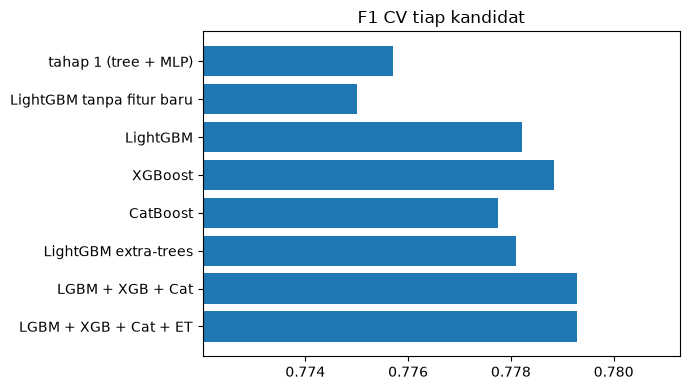

,AUC,logloss,F1_max,thr_terbaik,F1_thr_039
model,,,,,
tahap 1 (tree + MLP),0.8479,0.4705,0.7757,0.360,0.7749
LightGBM tanpa fitur baru,0.8469,0.4723,0.7750,0.370,0.7747
LightGBM,0.8514,0.4663,0.7782,0.385,0.7782
XGBoost,0.8516,0.4659,0.7788,0.385,0.7788
CatBoost,0.8495,0.4695,0.7778,0.400,0.7776
LightGBM extra-trees,0.8513,0.4666,0.7781,0.390,0.7781
LGBM + XGB + Cat,0.8521,0.4654,0.7793,0.395,0.7793
LGBM + XGB + Cat + ET,0.8525,0.4649,0.7793,0.390,0.7793


In [17]:
GRID = np.round(np.arange(0.30, 0.5001, 0.005), 3)
def f1c(y, p):
    pr = p[None, :] > GRID[:, None]; tp = (pr & (y == 1)).sum(1); return 2 * tp / (pr.sum(1) + y.sum())
def smooth(c, k=5): return np.convolve(np.pad(c, k // 2, mode="edge"), np.ones(k) / k, mode="valid")   # F1 per threshold, dihaluskan

L = {k: lg(v) for k, v in oof.items()}
CAND = {
    "tahap 1 (tree + MLP)": np.repeat(lg(p13[trm])[None, :], REPS, 0),
    "LightGBM tanpa fitur baru": L["lgbm_base"],
    "LightGBM": L["lgbm"],
    "XGBoost": L["xgb"],
    "CatBoost": L["cat"],
    "LightGBM extra-trees": L["lgbm_et"],
    "LGBM + XGB + Cat": (L["lgbm"] + L["xgb"] + L["cat"]) / 3,
    "LGBM + XGB + Cat + ET": (L["lgbm"] + L["xgb"] + L["cat"] + L["lgbm_et"]) / 4,
}
yc = y_all[CLEAN]; rows = []; curves = {}
for k, Z in CAND.items():
    P = sig(Z)[:, CLEAN]
    cur = [smooth(f1c(yc, P[r])) for r in range(REPS)]; mc = np.mean(cur, 0); curves[k] = mc
    rows.append(dict(model=k, AUC=np.mean([roc_auc_score(yc, P[r]) for r in range(REPS)]),
                     logloss=np.mean([log_loss(yc, P[r]) for r in range(REPS)]),
                     F1_max=mc.max(), thr_terbaik=GRID[mc.argmax()], F1_thr_039=mc[GRID == THRESHOLD][0]))
SEL = pd.DataFrame(rows).set_index("model")

plt.figure(figsize=(7, 4))
plt.barh(SEL.index[::-1], SEL.F1_max[::-1])
plt.xlim(SEL.F1_max.min() - 0.003, SEL.F1_max.max() + 0.002)
plt.title("F1 CV tiap kandidat")
plt.tight_layout()
plt.show()
SEL.round(4)

Fitur retake/partner menaikkan F1 sekitar 0.003 dan AUC sekitar 0.005 dibanding LightGBM tanpa fitur itu. Gabungan 4 model
(LGBM + XGB + Cat + extra-trees) punya AUC dan logloss terbaik dengan F1 setara yang tertinggi, jadi ini yang kami pilih.

## 6. Evaluasi model terpilih

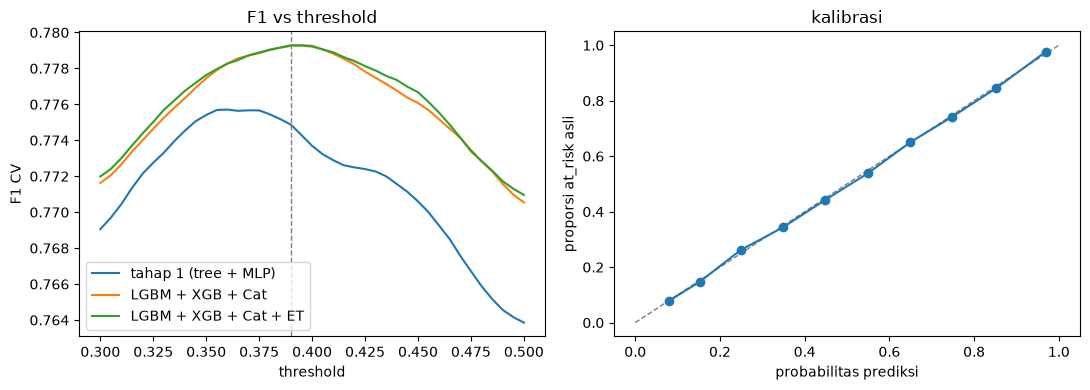

threshold,0.360,0.365,0.370,0.375,0.380,0.385,0.390,0.395,0.400,0.405,0.410,0.415,0.420,0.425,0.430
F1,0.7783,0.7785,0.7787,0.7789,0.779,0.7792,0.7793,0.7793,0.7792,0.7791,0.7789,0.7786,0.7784,0.7781,0.7779


In [18]:
P_fin = sig(CAND["LGBM + XGB + Cat + ET"])
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for k in ["tahap 1 (tree + MLP)", "LGBM + XGB + Cat", "LGBM + XGB + Cat + ET"]:
    ax[0].plot(GRID, curves[k], label=k)
ax[0].axvline(THRESHOLD, color="gray", ls="--", lw=1)
ax[0].set_xlabel("threshold"); ax[0].set_ylabel("F1 CV"); ax[0].set_title("F1 vs threshold"); ax[0].legend()

p_mean = P_fin[:, CLEAN].mean(0); idx = np.digitize(p_mean, np.linspace(0, 1, 11)[1:-1])
ax[1].plot([0, 1], [0, 1], color="gray", ls="--", lw=1)
ax[1].plot([p_mean[idx == i].mean() for i in range(10)], [yc[idx == i].mean() for i in range(10)], marker="o")
ax[1].set_xlabel("probabilitas prediksi"); ax[1].set_ylabel("proporsi at_risk asli"); ax[1].set_title("kalibrasi")
plt.tight_layout()
plt.show()

tab = pd.DataFrame({"threshold": GRID, "F1": curves["LGBM + XGB + Cat + ET"]})
tab[(tab.threshold >= 0.36) & (tab.threshold <= 0.43)].round(4).set_index("threshold").T

Kurva F1 cukup datar di 0.38 sampai 0.40, puncaknya di 0.39 sampai 0.395. Kami pakai threshold 0.39.

In [19]:
pred = P_fin[:, CLEAN] > THRESHOLD
per_rep = pd.DataFrame([dict(repeat=r, F1=f1_score(yc, pred[r]), precision=precision_score(yc, pred[r]),
                             recall=recall_score(yc, pred[r]), AUC=roc_auc_score(yc, P_fin[r, CLEAN])) for r in range(REPS)])
print(per_rep.round(4).to_string(index=False))
print("F1 rata-rata:", round(per_rep.F1.mean(), 4))
print()
print("confusion matrix (repeat 0)")
print(pd.DataFrame(confusion_matrix(yc, pred[0]), index=["asli 0", "asli 1"], columns=["pred 0", "pred 1"]))

 repeat     F1  precision  recall    AUC
      0 0.7788     0.7401  0.8217 0.8524
      1 0.7805     0.7441  0.8206 0.8526
      2 0.7791     0.7418  0.8203 0.8524
F1 rata-rata: 0.7795

confusion matrix (repeat 0)
        pred 0  pred 1
asli 0    8297    3947
asli 1    2440   11242


In [20]:
trc = full[trm][CLEAN]
segment = np.where(trc.no_vle == 1, "tanpa VLE", np.where(trc.has_score == 0, "tanpa nilai", "lengkap"))
rows = []
for grp_name, grp in [("segmen", segment), ("modul", trc.code_module.astype(str).values)]:
    for v in np.unique(grp):
        mk = grp == v
        rows.append(dict(kelompok=grp_name, nilai=v, n=mk.sum(), at_risk=yc[mk].mean(),
                         F1=np.mean([f1_score(yc[mk], pred[r][mk]) for r in range(REPS)]),
                         AUC=np.mean([roc_auc_score(yc[mk], P_fin[r, CLEAN][mk]) for r in range(REPS)])))
pd.DataFrame(rows).set_index(["kelompok", "nilai"]).round(3)

n  at_risk     F1    AUC
kelompok nilai                                    
segmen   lengkap      15966    0.407  0.658  0.774
         tanpa VLE     3723    0.952  0.977  0.911
         tanpa nilai   6237    0.583  0.814  0.868
modul    M01            602    0.304  0.607  0.806
         M02           6364    0.523  0.771  0.847
         M03           3568    0.620  0.840  0.877
         M04           6159    0.526  0.778  0.851
         M05           2342    0.439  0.727  0.847
         M06           5066    0.583  0.819  0.871
         M07           1825    0.406  0.597  0.697

Model hampir sempurna di siswa tanpa VLE, tapi di segmen lengkap F1 hanya sekitar 0.66. Di segmen ini banyak siswa yang
datanya mirip tapi hasilnya beda, jadi sebagian besar kesalahan ada di sini. Modul M07 juga paling sulit (AUC sekitar 0.70).

## 7. Training final dan submission

Untuk baris train, fitur label partner dibuat secara out-of-fold (seperti saat CV). Untuk test, semua label train dianggap
diketahui. Setiap model dilatih di seluruh train dengan 3 seed x 2 pembagian fold, lalu logit keempat model dirata-rata.

Catatan: LightGBM, XGBoost, dan CatBoost dilatih multi-thread, jadi hasil penjumlahan floating-point bisa sedikit berbeda antar run. Probabilitas berubah di sekitar 1e-15, tapi beberapa baris yang probabilitasnya tepat di sekitar threshold 0.39 bisa pindah kelas. Di mesin kami, perbedaan antar run paling banyak 13 dari 6502 baris; file yang kami submit adalah hasil run notebook ini.

In [21]:
t0 = time.time(); R_ = 2; SEEDS = [0, 1, 2]; n = R_ * len(SEEDS)
LT = {k: np.zeros((~trm).sum()) for k in ["lgbm", "xgb", "cat", "lgbm_et"]}
for r in range(R_):
    Xtr = None
    for a, b in StratifiedKFold(5, shuffle=True, random_state=500 + r).split(tri, y_all):
        known = np.zeros(N, bool); known[tri[a]] = True
        Xb = make_X(known)[trm]
        if Xtr is None: Xtr = Xb.copy()
        Xtr.iloc[b] = Xb.iloc[b].values
    Xte = make_X(trm.copy())[~trm]
    Xtc, Xtec = cat_cast(Xtr), cat_cast(Xte)
    for s in SEEDS:
        LT["lgbm"] += lg(model("lgbm", s).fit(Xtr, y_all).predict_proba(Xte)[:, 1]) / n
        LT["xgb"] += lg(model("xgb", s).fit(Xtr, y_all).predict_proba(Xte)[:, 1]) / n
        LT["cat"] += lg(model("cat", s).fit(Xtc, y_all, cat_features=NOMINAL).predict_proba(Xtec)[:, 1]) / n
    for s in SEEDS:
        LT["lgbm_et"] += lg(lgbm_et(s).fit(Xtr, y_all).predict_proba(Xte)[:, 1]) / n
    print(f"bagian {r + 1}/{R_} selesai ({time.time() - t0:.0f} detik)", flush=True)

p_test = sig((lg(sig(LT["lgbm"])) + lg(sig(LT["xgb"])) + lg(sig(LT["cat"])) + LT["lgbm_et"]) / 4)

bagian 1/2 selesai (162 detik)


bagian 2/2 selesai (334 detik)


In [22]:
submission = pd.DataFrame({"id": full.loc[~trm, "id"].values, TARGET: (p_test > THRESHOLD).astype(int)})
assert list(submission.columns) == list(sub.columns) and submission["id"].equals(sub["id"])
submission.to_csv("submission_final_exp30.csv", index=False)
print(submission.shape, "| proporsi at_risk:", round(submission[TARGET].mean(), 3))
submission.head()

(6502, 2) | proporsi at_risk: 0.578


,id,at_risk
0,26092,0
1,26093,0
2,26094,0
3,26095,0
4,26096,1
